# Task 1a: noise statistics and the clean-label reference

CIFAR-10N "worst" labels on the 45,000 training images: noise rate, the 10×10 confusion matrix of noisy against clean labels, and where the human mistakes concentrate. The same numbers for the synthetic (symmetric) labels are kept for Task 5.

Then the reference ResNet-18 is trained on the clean labels for the full 60 epochs, and its final-epoch test predictions are written to `predictions/t1_clean_ref.csv`.

Runtime on an A100: about 10 minutes.

In [5]:
import sys, zipfile
from pathlib import Path
from google.colab import drive
drive.mount("/content/drive")
ROOT = Path("/content/drive/MyDrive/cv_bootcamp")
if not (ROOT / "data" / "labels.csv").exists():
    zipfile.ZipFile("/content/drive/MyDrive/cv_bootcamp.zip").extractall(ROOT.parent)
sys.path.insert(0, str(ROOT / "code"))
print("project folder:", ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
project folder: /content/drive/MyDrive/cv_bootcamp


In [6]:
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import cvlib as cv

WORK = ROOT / "work"
PRED = ROOT / "predictions"
WORK.mkdir(exist_ok=True)
PRED.mkdir(exist_ok=True)

print("device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")
data = cv.Data(ROOT)
print("train", len(data.train_idx), " val", len(data.val_idx), " test", len(data.x_test))
print("classes:", data.classes)

device: NVIDIA A100-SXM4-80GB
train 45000  val 5000  test 10000
classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## Noise rate and confusion matrix

In [7]:
lab = data.labels
tr, va = data.train_idx, data.val_idx
noisy, clean, synth = (lab[c].to_numpy() for c in ["noisy_label", "clean_label", "synthetic_label"])

noise_rate = float((noisy[tr] != clean[tr]).mean())
print(f"noise rate, train (human labels):     {noise_rate:.4f}  ({(noisy[tr] != clean[tr]).sum()} of {len(tr)})")
print(f"noise rate, val (human labels):       {(noisy[va] != clean[va]).mean():.4f}")
print(f"noise rate, train (synthetic labels): {(synth[tr] != clean[tr]).mean():.4f}")

# rows = true (clean) class, columns = noisy label
cm = pd.crosstab(pd.Series(clean[tr], name="clean"), pd.Series(noisy[tr], name="noisy")).reindex(index=range(10), columns=range(10), fill_value=0)
cm.index, cm.columns = data.classes, data.classes
cm.to_csv(WORK / "t1_confusion_noisy_vs_clean.csv")
cm

noise rate, train (human labels):     0.4024  (18109 of 45000)
noise rate, val (human labels):       0.3990
noise rate, train (synthetic labels): 0.4010


,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
airplane,2925,293,314,89,94,105,85,75,379,146
automobile,191,2657,63,116,80,68,60,64,71,1126
bird,263,165,2842,212,254,216,222,147,106,77
cat,180,160,354,2168,194,924,206,106,91,86
deer,184,142,316,184,2195,491,174,683,94,50
dog,150,131,240,834,183,2620,123,136,55,61
frog,170,166,373,350,229,257,2676,124,96,62
horse,179,120,111,100,233,289,101,3246,77,50
ship,369,333,94,65,96,79,71,99,3076,214
truck,180,1247,81,87,78,81,52,68,115,2486


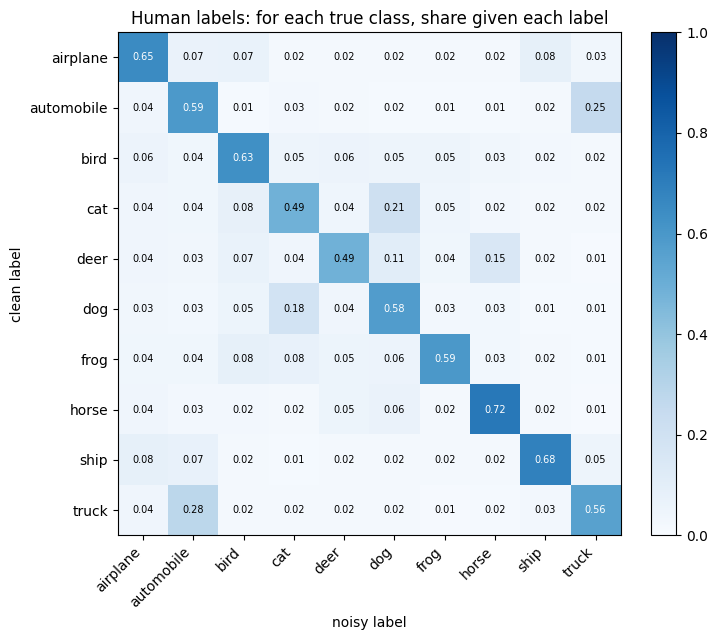

In [8]:
def plot_cm(cm, title, path):
    rows = cm.div(cm.sum(1), axis=0)
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    im = ax.imshow(rows.values, cmap="Blues", vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            v = rows.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.5 else "black")
    ax.set_xticks(range(10), cm.columns, rotation=45, ha="right")
    ax.set_yticks(range(10), cm.index)
    ax.set_xlabel("noisy label")
    ax.set_ylabel("clean label")
    ax.set_title(title)
    fig.colorbar(im, fraction=0.046)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()

plot_cm(cm, "Human labels: for each true class, share given each label", WORK / "t1_confusion_human.png")

In [9]:
# which (true -> given) pairs carry the noise, and the same per unordered class pair
def top_pairs(given, n=10):
    wrong = given[tr] != clean[tr]
    s = pd.Series(list(zip(clean[tr][wrong], given[tr][wrong]))).value_counts()
    total = wrong.sum()
    out = pd.DataFrame({"true -> given": [f"{data.classes[a]} -> {data.classes[b]}" for a, b in s.index],
                        "count": s.values, "share of all wrong labels": (s.values / total).round(4)})
    return out.head(n)

def unordered_pairs(given, n=6):
    wrong = given[tr] != clean[tr]
    s = pd.Series([tuple(sorted(p)) for p in zip(clean[tr][wrong], given[tr][wrong])]).value_counts()
    total = wrong.sum()
    return pd.DataFrame({"pair": [f"{data.classes[a]} / {data.classes[b]}" for a, b in s.index],
                         "count": s.values, "share": (s.values / total).round(4),
                         "cumulative share": (s.values.cumsum() / total).round(4)}).head(n)

print("human labels, ordered pairs")
display(top_pairs(noisy))
print("human labels, unordered pairs")
display(unordered_pairs(noisy))

per_class = pd.DataFrame({
    "noise rate (by true class)": [(noisy[tr][clean[tr] == k] != k).mean() for k in range(10)],
    "synthetic noise rate (by true class)": [(synth[tr][clean[tr] == k] != k).mean() for k in range(10)],
}, index=data.classes).round(4)
per_class

human labels, ordered pairs


,true -> given,count,share of all wrong labels
0,truck -> automobile,1247,0.0689
1,automobile -> truck,1126,0.0622
2,cat -> dog,924,0.0510
3,dog -> cat,834,0.0461
4,deer -> horse,683,0.0377
5,deer -> dog,491,0.0271
6,airplane -> ship,379,0.0209
7,frog -> bird,373,0.0206
8,ship -> airplane,369,0.0204
9,cat -> bird,354,0.0195


human labels, unordered pairs


,pair,count,share,cumulative share
0,automobile / truck,2373,0.1310,0.1310
1,cat / dog,1758,0.0971,0.2281
2,deer / horse,916,0.0506,0.2787
3,airplane / ship,748,0.0413,0.3200
4,deer / dog,674,0.0372,0.3572
5,bird / frog,595,0.0329,0.3901


,noise rate (by true class),synthetic noise rate (by true class)
airplane,0.3507,0.3982
automobile,0.4090,0.4017
bird,0.3690,0.3894
cat,0.5149,0.4095
deer,0.5136,0.3980
dog,0.4220,0.4002
frog,0.4057,0.3966
horse,0.2796,0.4137
ship,0.3158,0.4026
truck,0.4445,0.4000


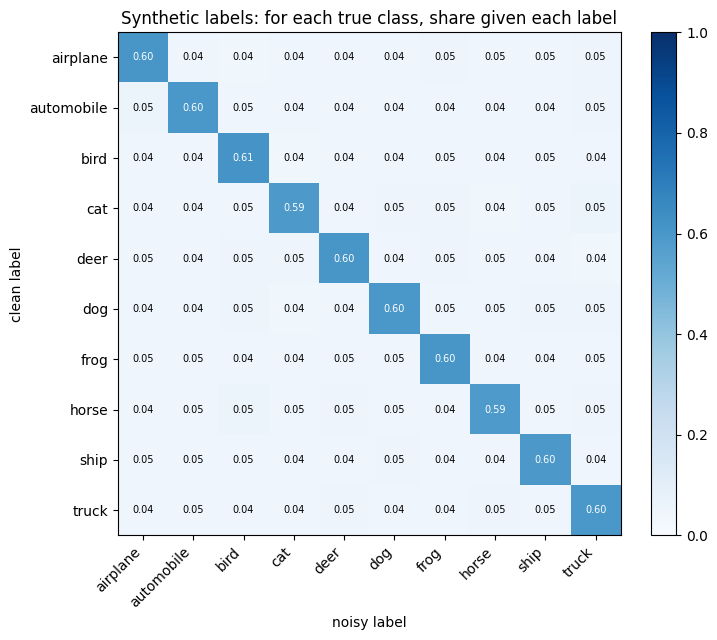

synthetic labels, unordered pairs


,pair,count,share,cumulative share
0,airplane / frog,436,0.0242,0.0242
1,deer / frog,433,0.0240,0.0482
2,horse / truck,431,0.0239,0.0720
3,dog / ship,429,0.0238,0.0958
4,bird / horse,429,0.0238,0.1196
5,deer / horse,429,0.0238,0.1434


In [10]:
# synthetic labels for comparison (Task 5): the same overall rate, spread evenly over the other classes
cm_syn = pd.crosstab(pd.Series(clean[tr], name="clean"), pd.Series(synth[tr], name="synthetic")).reindex(index=range(10), columns=range(10), fill_value=0)
cm_syn.index, cm_syn.columns = data.classes, data.classes
cm_syn.to_csv(WORK / "t1_confusion_synthetic_vs_clean.csv")
plot_cm(cm_syn, "Synthetic labels: for each true class, share given each label", WORK / "t1_confusion_synthetic.png")
print("synthetic labels, unordered pairs")
display(unordered_pairs(synth))

cv.update_results(WORK, task1={"noise_rate": round(noise_rate, 4)})
stats = {
    "noise_rate_train": noise_rate,
    "noise_rate_val": float((noisy[va] != clean[va]).mean()),
    "synthetic_noise_rate_train": float((synth[tr] != clean[tr]).mean()),
    "n_mislabeled_train": int((noisy[tr] != clean[tr]).sum()),
    "top_pairs_human": unordered_pairs(noisy).to_dict("records"),
    "top_pairs_synthetic": unordered_pairs(synth).to_dict("records"),
}
_ = (WORK / "t1_noise_stats.json").write_text(json.dumps(stats, indent=2))

## Clean-label reference model

ResNet-18 from `model.py`, trained from scratch on the clean labels with the shared setup from `cvlib.py` (SGD with Nesterov momentum, lr 0.1 with per-step cosine decay, weight decay 5e-4, batch 128, random crop and flip, 60 epochs, seed 42). This is the only training run that uses clean labels.

Validation and test probabilities are stored for every epoch. The submitted predictions are from the final epoch.

In [11]:
print(json.dumps(cv.SETUP, indent=2))
cv.update_results(WORK, seed=cv.SEED, training_setup=cv.SETUP)

RUN = WORK / "t1_clean_ref.npz"
if RUN.exists():
    run = dict(np.load(RUN))
    print("loaded", RUN.name)
else:
    rec = cv.Recorder(data, noisy[va])          # validation accuracy against the noisy val labels
    net = cv.train(data, tr, clean[tr], on_epoch=rec, tag="clean ref")
    rec.save(RUN)
    torch.save(net.state_dict(), WORK / "t1_clean_ref.pt")
    run = dict(np.load(RUN))

{
  "optimizer": "SGD (momentum 0.9, nesterov, weight decay 5e-4)",
  "learning_rate_schedule": "cosine annealing per step, 0.1 to 0 over 60 epochs, no warmup",
  "batch_size": 128,
  "epochs": 60,
  "augmentation": "random crop 32x32 with 4-pixel zero padding, random horizontal flip"
}
clean ref epoch  1  loss 1.9348  val_acc 0.3012  (17s)
clean ref epoch  5  loss 0.8940  val_acc 0.4834  (34s)
clean ref epoch 10  loss 0.5348  val_acc 0.5246  (54s)
clean ref epoch 15  loss 0.4252  val_acc 0.5548  (74s)
clean ref epoch 20  loss 0.3558  val_acc 0.5536  (94s)
clean ref epoch 25  loss 0.2972  val_acc 0.5654  (114s)
clean ref epoch 30  loss 0.2450  val_acc 0.5592  (135s)
clean ref epoch 35  loss 0.1834  val_acc 0.5678  (155s)
clean ref epoch 40  loss 0.1230  val_acc 0.5820  (175s)
clean ref epoch 45  loss 0.0635  val_acc 0.5884  (195s)
clean ref epoch 50  loss 0.0188  val_acc 0.5910  (215s)
clean ref epoch 55  loss 0.0071  val_acc 0.5910  (235s)
clean ref epoch 60  loss 0.0052  val_acc 0.59

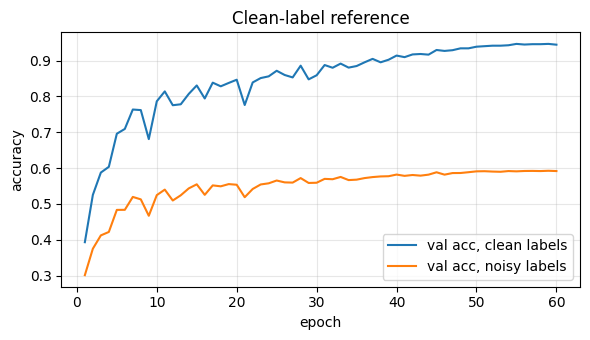

final epoch: val acc on clean labels 0.9446, on noisy labels 0.5918
agreement of a perfect classifier with the noisy val labels would be 0.6010
{
  "task1": {
    "noise_rate": 0.4024,
    "val_acc_noisy_labels__clean_ref_model": 0.5918
  },
  "seed": 42,
  "training_setup": {
    "optimizer": "SGD (momentum 0.9, nesterov, weight decay 5e-4)",
    "learning_rate_schedule": "cosine annealing per step, 0.1 to 0 over 60 epochs, no warmup",
    "batch_size": 128,
    "epochs": 60,
    "augmentation": "random crop 32x32 with 4-pixel zero padding, random horizontal flip"
  },
  "extra": {
    "clean_ref_val_acc_clean": 0.9446
  }
}


In [12]:
vp = run["val_probs"].astype(np.float32)                 # (epochs, 5000, 10)
acc_noisy = (vp.argmax(2) == noisy[va]).mean(1)
acc_clean = (vp.argmax(2) == clean[va]).mean(1)
ep = np.arange(1, len(acc_noisy) + 1)

plt.figure(figsize=(6, 3.5))
plt.plot(ep, acc_clean, label="val acc, clean labels")
plt.plot(ep, acc_noisy, label="val acc, noisy labels")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.title("Clean-label reference"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(WORK / "t1_clean_ref_curve.png", dpi=150); plt.show()

cv.write_preds(PRED / "t1_clean_ref.csv", run["test_probs"][-1].astype(np.float32))
print(f"final epoch: val acc on clean labels {acc_clean[-1]:.4f}, on noisy labels {acc_noisy[-1]:.4f}")
print(f"agreement of a perfect classifier with the noisy val labels would be {1 - stats['noise_rate_val']:.4f}")

cv.update_results(WORK, task1={"val_acc_noisy_labels__clean_ref_model": round(float(acc_noisy[-1]), 4)},
                  extra={"clean_ref_val_acc_clean": round(float(acc_clean[-1]), 4)})
print(json.dumps(cv.load_results(WORK), indent=2))